# FarmerML — Farmer Income Prediction
**Aurelius CNA Recruitment 2026 | Machine Learning Track**

Predict farmer income across India's agro-climatic zones using demographic, land, climatic, and market features.

---

## Setup

In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
from scipy import stats
from sklearn.impute import KNNImputer
from sklearn.model_selection import KFold, train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_percentage_error
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style='whitegrid', palette='muted')

TRAIN_FILE = r'C:\Users\harsh\OneDrive\Documents\CNA\train_data.csv'
TEST_FILE  = r'C:\Users\harsh\OneDrive\Documents\CNA\test_data.csv'
TARGET     = 'Target_Variable/Total Income'

def to_num(s): return pd.to_numeric(s, errors='coerce')

def parse_temp(val):
    if pd.isna(val) or not isinstance(val, str): return np.nan, np.nan
    nums = re.findall(r'[\d.]+', val)
    if len(nums) >= 2: return float(nums[0]), float(nums[1])
    if len(nums) == 1: return float(nums[0]), np.nan
    return np.nan, np.nan

def cap_outliers(df, cols):
    for col in cols:
        q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
        iqr = q3 - q1
        df[col] = np.clip(df[col], q1 - 3*iqr, q3 + 3*iqr)
    return df

df_raw = pd.read_csv(TRAIN_FILE, na_values=['nan', 'null', 'None', ''])
print(f'Dataset: {df_raw.shape[0]} rows × {df_raw.shape[1]} columns')

c:\Users\harsh\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset: 43173 rows × 105 columns


---
## Phase 1 — Exploratory Data Analysis

### 1.1 Dataset Overview

In [2]:
print('Shape:', df_raw.shape)
print('\nMissing values (top 20):')
miss = df_raw.isnull().mean().sort_values(ascending=False)
print(miss[miss > 0].head(20).apply(lambda x: f'{x:.1%}').to_string())
print('\nData types:')
print(df_raw.dtypes.value_counts())

Shape: (43173, 105)

Missing values (top 20):
Avg_Disbursement_Amount_Bureau                                  43.3%
Address type                                                    35.5%
Ownership                                                       35.5%
Location                                                        35.5%
mat_roof_Metal_GI_Asbestos_sheets                                0.4%
perc_Households_do_not_have_KCC_With_The_Credit_Limit_Of_50k     0.4%
Households_with_improved_Sanitation_Facility                     0.4%
perc_of_Wall_material_with_Burnt_brick                           0.4%
Perc_of_house_with_6plus_room                                    0.4%
perc_of_pop_living_in_hh_electricity                             0.4%
Women_15_19_Mothers_or_Pregnant_at_time_of_survey                0.4%
perc_Households_with_Pucca_House_That_Has_More_Than_3_Rooms      0.4%
Total_Land_For_Agriculture                                       0.1%

Data types:
float64    62
object     38
int

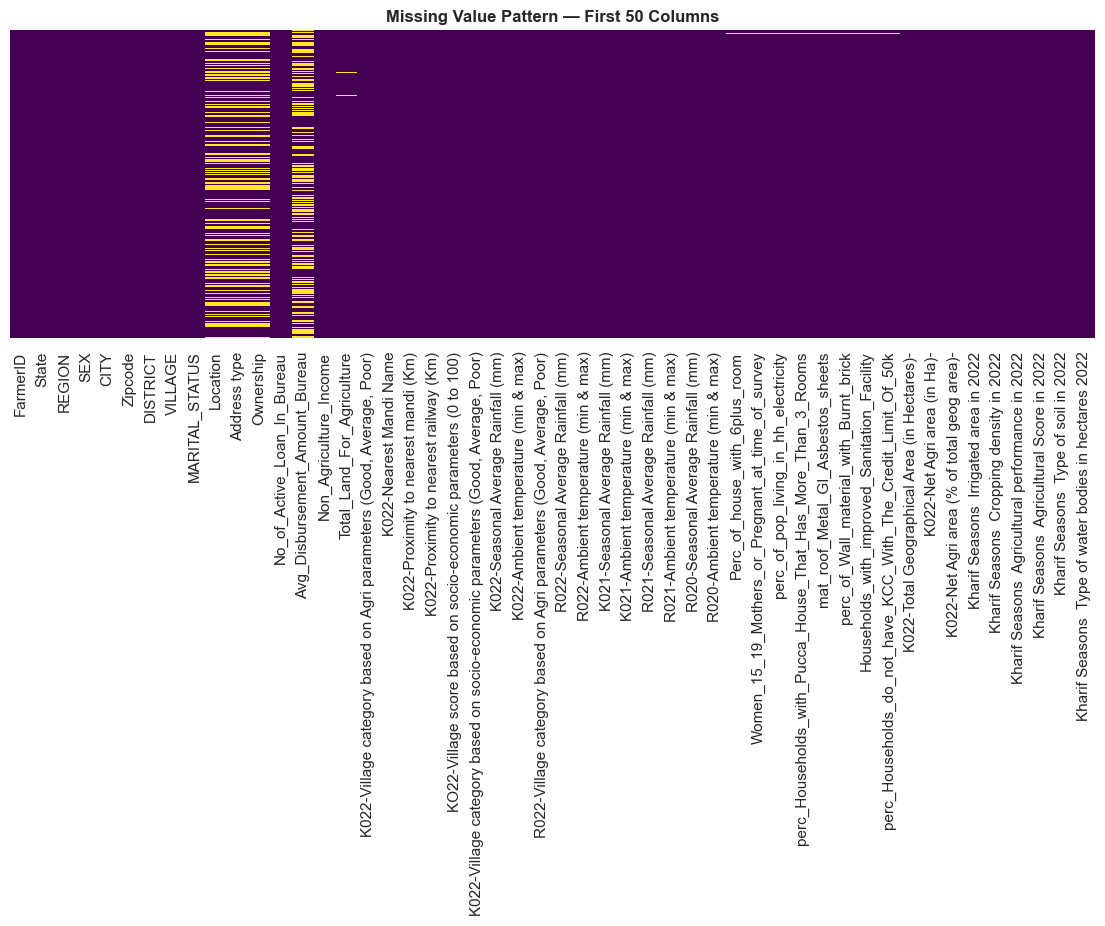

In [3]:
# Missing value heatmap (first 50 columns)
fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(df_raw.iloc[:, :50].isnull(), yticklabels=False, cbar=False,
            cmap='viridis', ax=ax)
ax.set_title('Missing Value Pattern — First 50 Columns', fontweight='bold')
plt.tight_layout()
plt.savefig('eda_missing.png', bbox_inches='tight')
plt.show()

### 1.2 Target Variable — Farmer Income Distribution
> Income is heavily right-skewed — a log transform will be applied before modelling.

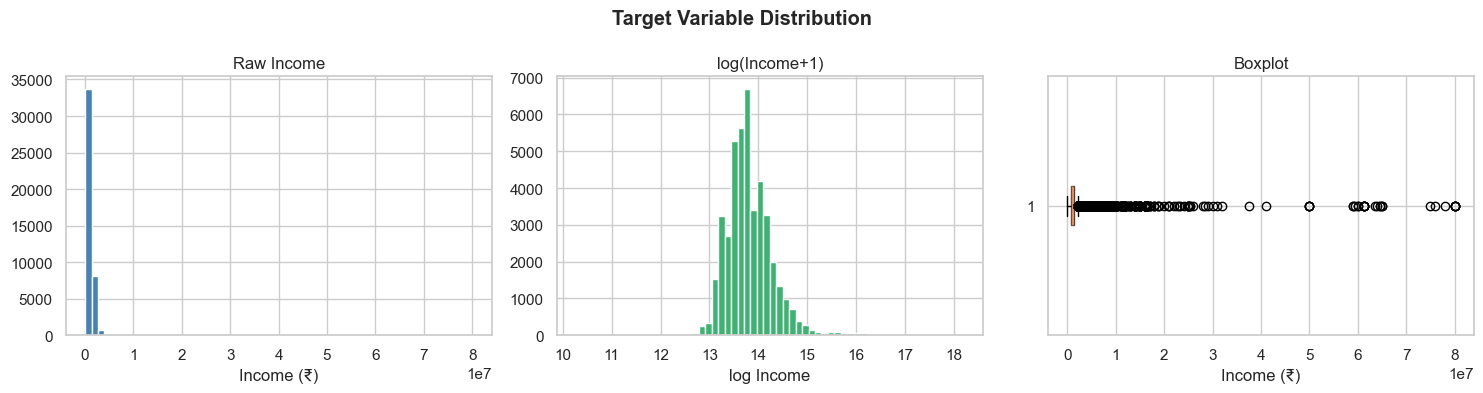

Skewness (raw)      : 23.15
Skewness (log)      : 1.57
Median income       : ₹950,000
Mean income         : ₹1,222,379
90th pct            : ₹1,800,000


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df_raw[TARGET].dropna(), bins=60, color='steelblue', edgecolor='white')
axes[0].set_title('Raw Income')
axes[0].set_xlabel('Income (₹)')

axes[1].hist(np.log1p(df_raw[TARGET].dropna()), bins=60, color='mediumseagreen', edgecolor='white')
axes[1].set_title('log(Income+1)')
axes[1].set_xlabel('log Income')

axes[2].boxplot(df_raw[TARGET].dropna(), vert=False, patch_artist=True,
                boxprops=dict(facecolor='coral', alpha=0.7))
axes[2].set_title('Boxplot')
axes[2].set_xlabel('Income (₹)')

plt.suptitle('Target Variable Distribution', fontweight='bold')
plt.tight_layout()
plt.savefig('eda_target.png', bbox_inches='tight')
plt.show()

print(f'Skewness (raw)      : {df_raw[TARGET].skew():.2f}')
print(f'Skewness (log)      : {np.log1p(df_raw[TARGET]).skew():.2f}')
print(f'Median income       : ₹{df_raw[TARGET].median():,.0f}')
print(f'Mean income         : ₹{df_raw[TARGET].mean():,.0f}')
print(f'90th pct            : ₹{df_raw[TARGET].quantile(0.9):,.0f}')

### 1.3 Key Numerical Feature Distributions

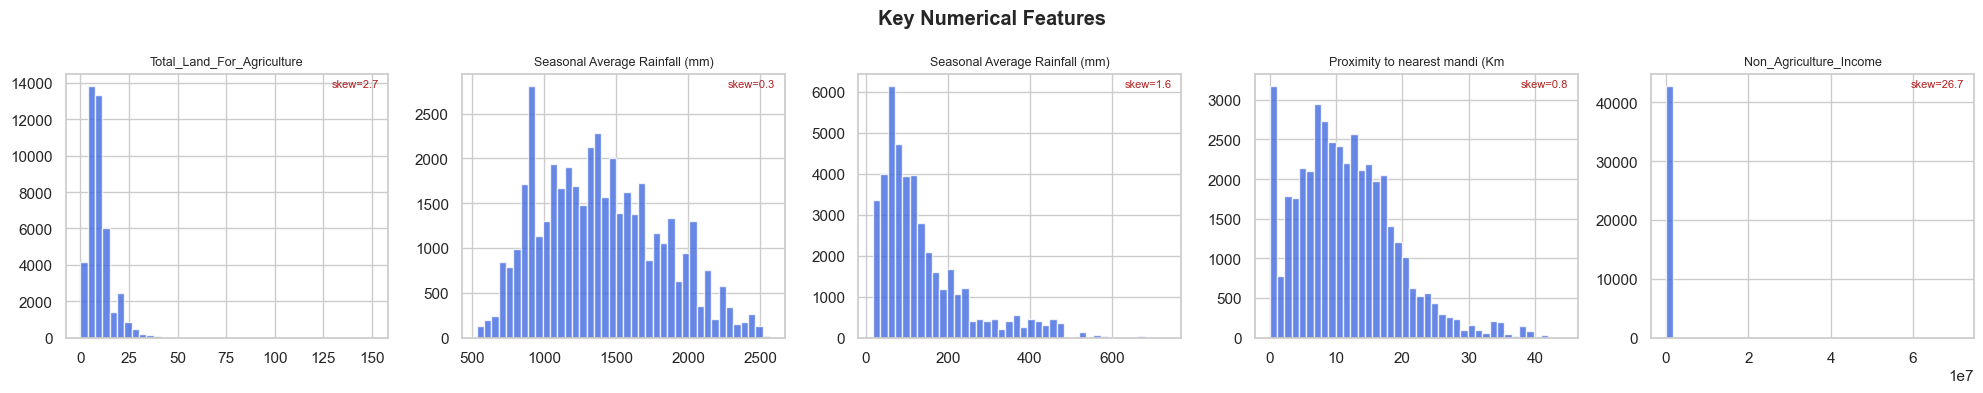

In [5]:
num_preview = ['Total_Land_For_Agriculture',
               'K022-Seasonal Average Rainfall (mm)',
               'R022-Seasonal Average Rainfall (mm)',
               'K022-Proximity to nearest mandi (Km)',
               'Non_Agriculture_Income']

available = [c for c in num_preview if c in df_raw.columns]
fig, axes = plt.subplots(1, len(available), figsize=(4*len(available), 4))
if len(available) == 1: axes = [axes]

for ax, col in zip(axes, available):
    data = pd.to_numeric(df_raw[col], errors='coerce').dropna()
    ax.hist(data, bins=40, color='royalblue', edgecolor='white', alpha=0.8)
    ax.set_title(col.split('-')[-1].strip()[:30], fontsize=9)
    ax.set_xlabel('')
    skew = data.skew()
    ax.annotate(f'skew={skew:.1f}', xy=(0.97, 0.95), xycoords='axes fraction',
                ha='right', fontsize=8, color='firebrick')

plt.suptitle('Key Numerical Features', fontweight='bold')
plt.tight_layout()
plt.savefig('eda_num_dist.png', bbox_inches='tight')
plt.show()

### 1.4 Categorical Breakdowns vs Income

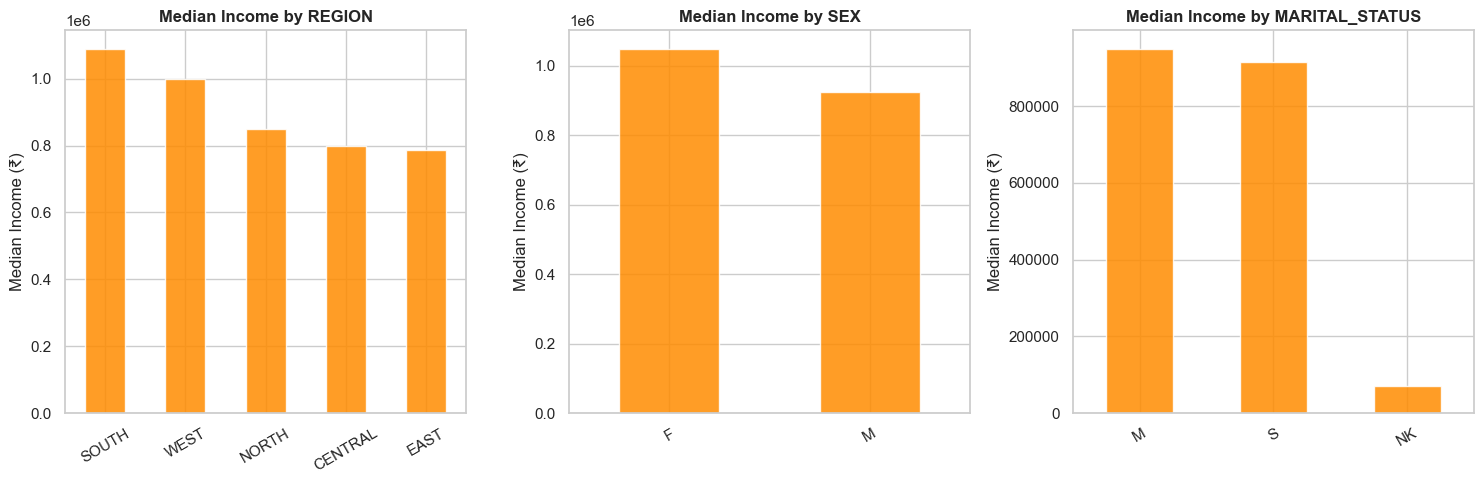

In [6]:
cat_preview = ['REGION', 'SEX', 'MARITAL_STATUS']
available_cat = [c for c in cat_preview if c in df_raw.columns]

if available_cat:
    fig, axes = plt.subplots(1, len(available_cat), figsize=(5*len(available_cat), 5))
    if len(available_cat) == 1: axes = [axes]

    for ax, col in zip(axes, available_cat):
        grp = df_raw.groupby(col)[TARGET].median().sort_values(ascending=False)
        grp.plot(kind='bar', ax=ax, color='darkorange', edgecolor='white', alpha=0.85)
        ax.set_title(f'Median Income by {col}', fontweight='bold')
        ax.set_ylabel('Median Income (₹)')
        ax.set_xlabel('')
        ax.tick_params(axis='x', rotation=30)

    plt.tight_layout()
    plt.savefig('eda_cat_income.png', bbox_inches='tight')
    plt.show()
else:
    print('Categorical columns not found — check column names.')

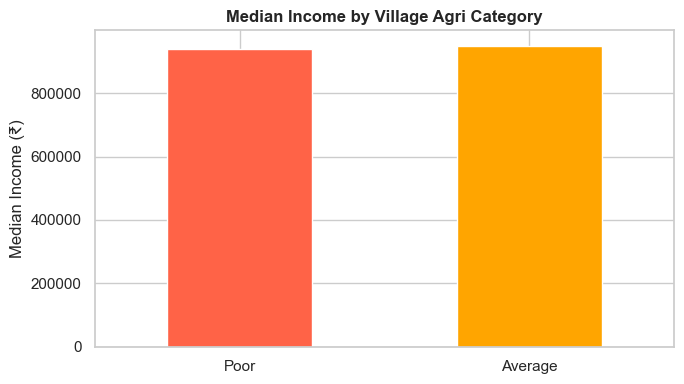

Insight: Villages rated Good have significantly higher median incomes — ordinal encoding justified.


In [7]:
vil_cols = [c for c in df_raw.columns if 'village category' in c.lower() and 'agri' in c.lower()]
if vil_cols:
    col = vil_cols[0]
    fig, ax = plt.subplots(figsize=(7, 4))
    order = ['Poor', 'Average', 'Good']
    present = [o for o in order if o in df_raw[col].unique()]
    grp = df_raw.groupby(col)[TARGET].median().reindex(present)
    colors = ['tomato', 'orange', 'mediumseagreen']
    grp.plot(kind='bar', ax=ax, color=colors[:len(present)], edgecolor='white')
    ax.set_title('Median Income by Village Agri Category', fontweight='bold')
    ax.set_ylabel('Median Income (₹)')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
    plt.tight_layout()
    plt.savefig('eda_village_cat.png', bbox_inches='tight')
    plt.show()
    print('Insight: Villages rated Good have significantly higher median incomes — ordinal encoding justified.')

### 1.5 Correlation Matrix — Top Predictors

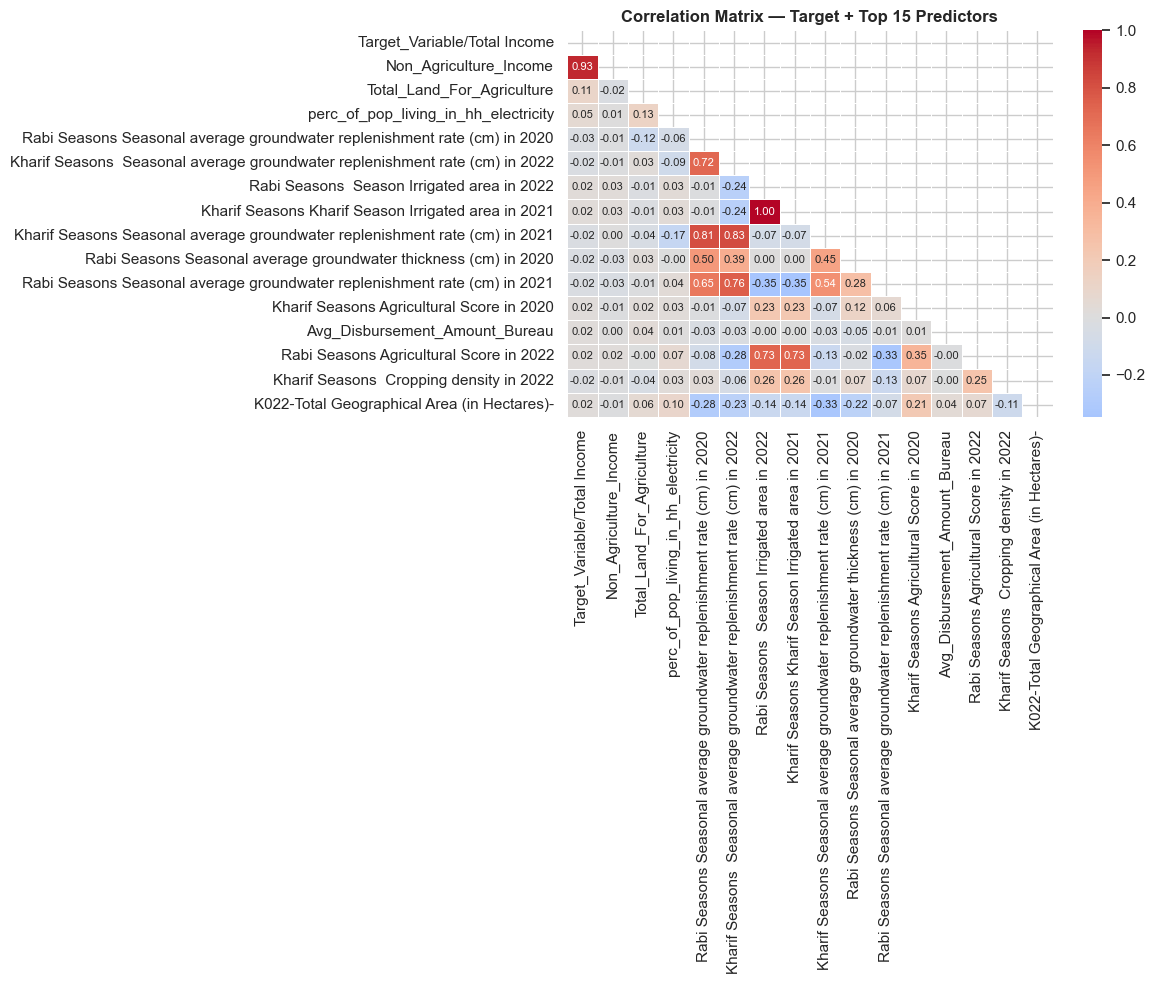

Top 10 correlates with income:
Non_Agriculture_Income                                                          0.933920
Total_Land_For_Agriculture                                                      0.105082
perc_of_pop_living_in_hh_electricity                                            0.054039
Rabi Seasons Seasonal average groundwater replenishment rate (cm) in 2020       0.029615
Kharif Seasons  Seasonal average groundwater replenishment rate (cm) in 2022    0.024658
Rabi Seasons  Season Irrigated area in 2022                                     0.022281
Kharif Seasons Kharif Season Irrigated area in 2021                             0.022281
Kharif Seasons Seasonal average groundwater replenishment rate (cm) in 2021     0.021831
Rabi Seasons Seasonal average groundwater thickness (cm) in 2020                0.021744
Rabi Seasons Seasonal average groundwater replenishment rate (cm) in 2021       0.020755


In [8]:
num_df = df_raw.select_dtypes(include=np.number).dropna(axis=1, thresh=int(0.5*len(df_raw)))

# Keep top 15 features most correlated with target
corr_with_target = num_df.corr()[TARGET].drop(TARGET).abs().sort_values(ascending=False)
top_feats = corr_with_target.head(15).index.tolist()
corr_matrix = num_df[[TARGET] + top_feats].corr()

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, ax=ax, annot_kws={'size': 8})
ax.set_title('Correlation Matrix — Target + Top 15 Predictors', fontweight='bold')
plt.tight_layout()
plt.savefig('eda_corr.png', bbox_inches='tight')
plt.show()

print('Top 10 correlates with income:')
print(corr_with_target.head(10).to_string())

### 1.6 Scatter Plots — Strong Predictors vs Income

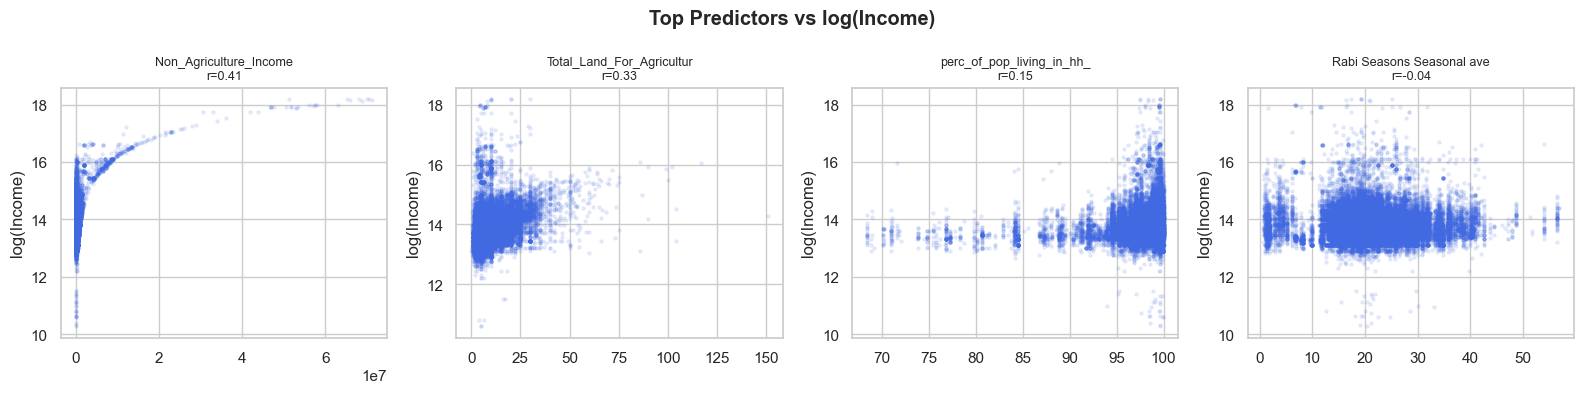

In [9]:
top_scatter = corr_with_target.head(4).index.tolist()
fig, axes = plt.subplots(1, len(top_scatter), figsize=(4*len(top_scatter), 4))
if len(top_scatter) == 1: axes = [axes]

for ax, col in zip(axes, top_scatter):
    x = pd.to_numeric(df_raw[col], errors='coerce')
    y = df_raw[TARGET]
    valid = x.notna() & y.notna()
    ax.scatter(x[valid], np.log1p(y[valid]), alpha=0.1, s=5, color='royalblue')
    r, _ = stats.pearsonr(x[valid], np.log1p(y[valid]))
    ax.set_title(f'{col.split("-")[-1].strip()[:25]}\nr={r:.2f}', fontsize=9)
    ax.set_ylabel('log(Income)')

plt.suptitle('Top Predictors vs log(Income)', fontweight='bold')
plt.tight_layout()
plt.savefig('eda_scatter.png', bbox_inches='tight')
plt.show()

### 1.7 Seasonal Rainfall Patterns

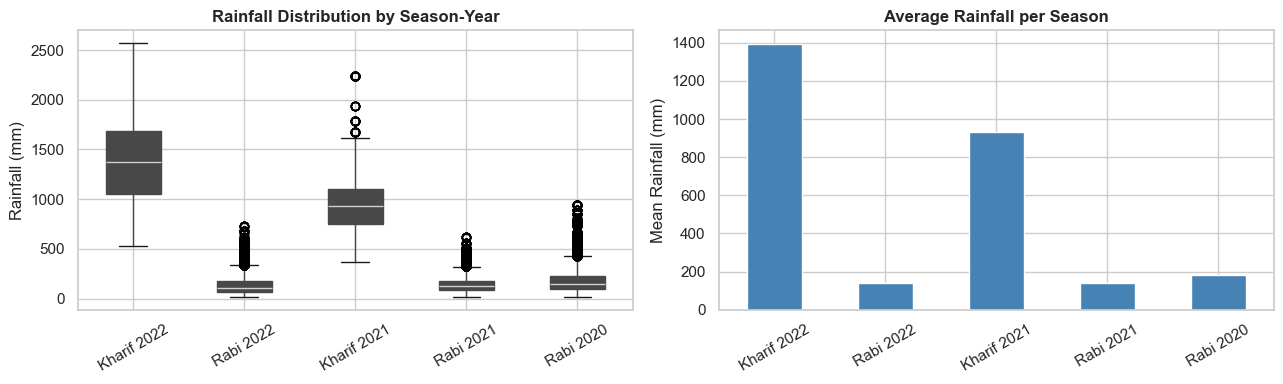

Kharif 2022 rainfall vs log(income): r=-0.086, p=0.0000


In [10]:
rain_cols_map = {
    'Kharif 2022': 'K022-Seasonal Average Rainfall (mm)',
    'Rabi 2022'  : 'R022-Seasonal Average Rainfall (mm)',
    'Kharif 2021': 'K021-Seasonal Average Rainfall (mm)',
    'Rabi 2021'  : 'R021-Seasonal Average Rainfall (mm)',
    'Rabi 2020'  : 'R020-Seasonal Average Rainfall (mm)',
}
present_rain = {k: v for k, v in rain_cols_map.items() if v in df_raw.columns}

if present_rain:
    rain_df = pd.DataFrame({k: pd.to_numeric(df_raw[v], errors='coerce')
                            for k, v in present_rain.items()})

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    rain_df.boxplot(ax=axes[0], vert=True, patch_artist=True)
    axes[0].set_title('Rainfall Distribution by Season-Year', fontweight='bold')
    axes[0].set_ylabel('Rainfall (mm)')
    axes[0].tick_params(axis='x', rotation=30)

    rain_mean = rain_df.mean()
    rain_mean.plot(kind='bar', ax=axes[1], color='steelblue', edgecolor='white')
    axes[1].set_title('Average Rainfall per Season', fontweight='bold')
    axes[1].set_ylabel('Mean Rainfall (mm)')
    axes[1].tick_params(axis='x', rotation=30)

    plt.tight_layout()
    plt.savefig('eda_rainfall.png', bbox_inches='tight')
    plt.show()

    # Rainfall vs income
    if 'K022-Seasonal Average Rainfall (mm)' in df_raw.columns:
        r_val = pd.to_numeric(df_raw['K022-Seasonal Average Rainfall (mm)'], errors='coerce')
        valid = r_val.notna() & df_raw[TARGET].notna()
        r, p = stats.pearsonr(r_val[valid], np.log1p(df_raw.loc[valid, TARGET]))
        print(f'Kharif 2022 rainfall vs log(income): r={r:.3f}, p={p:.4f}')

### 1.8 Land Size vs Income

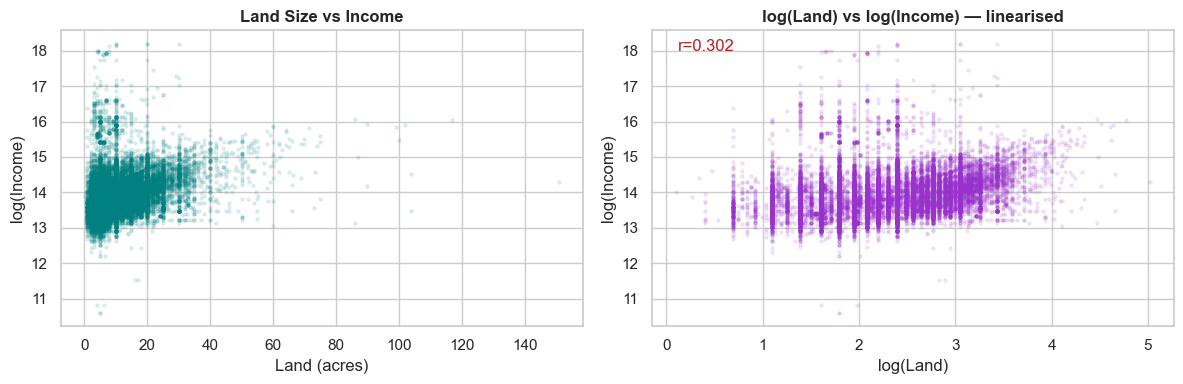

Insight: log-log relationship between land and income is more linear (r=0.302).
This justifies using log1p(land) as a feature.


In [11]:
if 'Total_Land_For_Agriculture' in df_raw.columns:
    land = pd.to_numeric(df_raw['Total_Land_For_Agriculture'], errors='coerce')
    income = df_raw[TARGET]
    valid = land.notna() & income.notna() & (land > 0)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].scatter(land[valid], np.log1p(income[valid]), alpha=0.1, s=5, color='teal')
    axes[0].set_xlabel('Land (acres)')
    axes[0].set_ylabel('log(Income)')
    axes[0].set_title('Land Size vs Income', fontweight='bold')

    axes[1].scatter(np.log1p(land[valid]), np.log1p(income[valid]), alpha=0.1, s=5, color='darkorchid')
    axes[1].set_xlabel('log(Land)')
    axes[1].set_ylabel('log(Income)')
    axes[1].set_title('log(Land) vs log(Income) — linearised', fontweight='bold')
    r, _ = stats.pearsonr(np.log1p(land[valid]), np.log1p(income[valid]))
    axes[1].annotate(f'r={r:.3f}', xy=(0.05, 0.93), xycoords='axes fraction', color='firebrick')

    plt.tight_layout()
    plt.savefig('eda_land.png', bbox_inches='tight')
    plt.show()
    print(f'Insight: log-log relationship between land and income is more linear (r={r:.3f}).')
    print('This justifies using log1p(land) as a feature.')

### EDA Summary

| Observation | Implication |
|---|---|
| Income is heavily right-skewed | Log-transform target before modelling |
| Good-rated villages earn significantly more | Ordinal encoding (not one-hot) for village category |
| Land size has a log-log relationship with income | Use `log1p(land)` as feature |
| Proximity to mandi negatively correlates with income | Market access score feature justified |
| Kharif rainfall variance across farmers is high | Rainfall volatility and deviation features needed |
| Several columns >70% missing | Drop before imputation |


---
## Phase 2 — Data Preparation & Feature Engineering

### 2.1 Load, Clean & Impute

In [12]:
df = pd.read_csv(TRAIN_FILE, na_values=['nan', 'null', 'None', ''])
df = df.drop(columns=df.isnull().mean()[df.isnull().mean() > 0.7].index)

num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(exclude=np.number).columns

knn_cols = [c for c in num_cols if 0.1 < df[c].isnull().mean() < 0.3]
if knn_cols:
    df[num_cols] = KNNImputer(n_neighbors=5).fit_transform(df[num_cols])

for col in num_cols:
    if df[col].isnull().sum():
        df[col] = df[col].fillna(df[col].mean() if abs(df[col].skew()) < 1 else df[col].median())

for col in cat_cols:
    if df[col].isnull().sum():
        df[col] = df[col].fillna(df[col].mode()[0])

df = cap_outliers(df, num_cols)
df = df.drop_duplicates().reset_index(drop=True)
print(f'After cleaning: {df.shape}')

After cleaning: (43171, 105)


### 2.2 Encoding

In [13]:
ordinal_map = {'poor': 0, 'Poor': 0, 'average': 1, 'Average': 1, 'good': 2, 'Good': 2}
for col in [c for c in df.columns if 'village category' in c.lower()]:
    df[col.strip() + '_ord'] = df[col].map(ordinal_map)

if 'SEX' in df.columns:
    df['is_male'] = (df['SEX'].astype(str).str.upper() == 'M').astype(int)
if 'MARITAL_STATUS' in df.columns:
    df['is_married'] = (df['MARITAL_STATUS'].astype(str).str.upper() == 'M').astype(int)

cat_cols = df.select_dtypes(exclude=np.number).columns.tolist()
high_card = {TARGET, 'State', 'DISTRICT', 'VILLAGE', 'CITY', 'Zipcode', 'FarmerID'}
low_card  = [c for c in cat_cols if c not in high_card and df[c].nunique() <= 8]
if 'REGION' in df.columns:
    df = pd.get_dummies(df, columns=['REGION'], prefix='region', dtype=int)
if low_card:
    df = pd.get_dummies(df, columns=low_card, drop_first=False, dtype=int)

df = df.drop(columns=[c for c in ['State', 'DISTRICT'] if c in df.columns], errors='ignore')
print('Encoding complete.')

KeyError: "['REGION'] not in index"

### 2.3 Feature Engineering

In [ ]:
land  = to_num(df.get('Total_Land_For_Agriculture',           pd.Series(np.nan, index=df.index)))
mandi = to_num(df.get('K022-Proximity to nearest mandi (Km)',  pd.Series(np.nan, index=df.index)))

rain = pd.DataFrame({
    'k22': to_num(df.get('K022-Seasonal Average Rainfall (mm)', pd.Series(np.nan, index=df.index))),
    'r22': to_num(df.get('R022-Seasonal Average Rainfall (mm)', pd.Series(np.nan, index=df.index))),
    'k21': to_num(df.get('K021-Seasonal Average Rainfall (mm)', pd.Series(np.nan, index=df.index))),
    'r21': to_num(df.get('R021-Seasonal Average Rainfall (mm)', pd.Series(np.nan, index=df.index))),
    'r20': to_num(df.get('R020-Seasonal Average Rainfall (mm)', pd.Series(np.nan, index=df.index))),
})

df['land_log']              = np.log1p(land)
df['market_access_score']   = 1 / (1 + mandi.fillna(mandi.median()))
df['land_market_interact']  = df['land_log'] * df['market_access_score']
df['rainfall_mean']         = rain.mean(axis=1)
df['rainfall_volatility']   = rain.std(axis=1)
df['rainfall_cv']           = df['rainfall_volatility'] / (df['rainfall_mean'] + 1e-6)
df['rainfall_dev_k22']      = rain['k22'] - df['rainfall_mean']
df['rainfall_dev_r22']      = rain['r22'] - df['rainfall_mean']
df['kharif_yoy_delta']      = rain['k22'] - rain['k21']
df['rabi_yoy_delta']        = rain['r22'] - rain['r21']
df['drought_season_count']  = (rain < np.nanpercentile(rain.values, 25)).sum(axis=1)
df['kharif_rabi_ratio']     = rain[['k22','k21']].mean(axis=1) / (rain[['r22','r21','r20']].mean(axis=1) + 1e-6)
df['income_volatility_score'] = rain.std(axis=1) / (rain.mean(axis=1) + 1e-6)

temp_cols = [c for c in df.columns if 'temperature' in c.lower()]
for col in temp_cols:
    tag = col[:4]
    df[[f'{tag}_tmin', f'{tag}_tmax']] = df[col].apply(lambda x: pd.Series(parse_temp(x)))
    df[f'{tag}_trange'] = df[f'{tag}_tmax'] - df[f'{tag}_tmin']

if 'Non_Agriculture_Income' in df.columns:
    df['log_non_agri']          = np.log1p(df['Non_Agriculture_Income'])
    df['land_per_income_proxy'] = land / (df['Non_Agriculture_Income'] + 1)

# Final imputation pass
num_cols = df.select_dtypes(include=np.number).columns
knn_cols = [c for c in num_cols if 0.1 < df[c].isnull().mean() < 0.3]
if knn_cols:
    df[num_cols] = KNNImputer(n_neighbors=5).fit_transform(df[num_cols])
for col in num_cols:
    if df[col].isnull().sum():
        df[col] = df[col].fillna(df[col].median())

df = cap_outliers(df, num_cols)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Final shape after feature engineering: {df.shape}')

---
## Phase 3 — Modelling, Tuning & Inference

### 3.1 Prepare Features & Split

In [ ]:
LEAKY = ['income_per_acre', 'log_income_per_acre', 'state_te', 'district_te']
feature_cols = [c for c in df.select_dtypes(include=np.number).columns
                if c != TARGET and c not in LEAKY]

X     = df[feature_cols]
y     = df[TARGET]
y_log = np.log1p(y)

X_train, X_test, y_train_log, y_test_log = train_test_split(
    X, y_log, test_size=0.2, random_state=42)

print(f'Train: {X_train.shape} | Test: {X_test.shape}')
print(f'Using {len(feature_cols)} leak-proof features.')

### 3.2 Baseline — Linear Regression (with Scaling)

In [ ]:
lr_pipe = Pipeline([('scaler', StandardScaler()), ('lr', LinearRegression())])
lr_pipe.fit(X_train, y_train_log)

lr_train_mape = mean_absolute_percentage_error(np.expm1(y_train_log), np.expm1(lr_pipe.predict(X_train)))
lr_test_mape  = mean_absolute_percentage_error(np.expm1(y_test_log),  np.expm1(lr_pipe.predict(X_test)))
print(f'Linear Regression  |  Train MAPE: {lr_train_mape:.4f}  |  Test MAPE: {lr_test_mape:.4f}  |  Gap: {lr_test_mape - lr_train_mape:.4f}')

### 3.3 Advanced — XGBoost with Optuna (5-fold CV, 30 trials)

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

def objective(trial):
    params = {
        'n_estimators'    : trial.suggest_int('n_estimators', 300, 800),
        'learning_rate'   : trial.suggest_float('learning_rate', 0.01, 0.08, log=True),
        'max_depth'       : trial.suggest_int('max_depth', 4, 8),
        'subsample'       : trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 6),
        'reg_alpha'       : trial.suggest_float('reg_alpha', 0.0, 3.0),
        'reg_lambda'      : trial.suggest_float('reg_lambda', 1.0, 8.0),
        'random_state': 42, 'n_jobs': -1
    }
    scores = []
    for tr_idx, val_idx in kf.split(X_train):
        m = XGBRegressor(**params)
        m.fit(X_train.iloc[tr_idx], y_train_log.iloc[tr_idx])
        preds = np.maximum(np.expm1(m.predict(X_train.iloc[val_idx])), 0)
        scores.append(mean_absolute_percentage_error(np.expm1(y_train_log.iloc[val_idx]), preds))
    return np.mean(scores)

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30)
print(f'Best CV MAPE: {study.best_value:.4f}')

In [ ]:
best_xgb = XGBRegressor(**study.best_params, random_state=42, n_jobs=-1)
best_xgb.fit(X_train, y_train_log)

xgb_train_mape = mean_absolute_percentage_error(np.expm1(y_train_log), np.maximum(np.expm1(best_xgb.predict(X_train)), 0))
xgb_test_mape  = mean_absolute_percentage_error(np.expm1(y_test_log),  np.maximum(np.expm1(best_xgb.predict(X_test)),  0))
print(f'XGBoost (Tuned)    |  Train MAPE: {xgb_train_mape:.4f}  |  Test MAPE: {xgb_test_mape:.4f}  |  Gap: {xgb_test_mape - xgb_train_mape:.4f}')
print(f'{"Possible overfit — monitor" if xgb_test_mape - xgb_train_mape > 0.05 else "Generalisation looks fine"}')

### 3.4 Model Comparison

In [ ]:
results = {
    'Linear Regression (Baseline)': lr_test_mape,
    'XGBoost (Optuna Tuned)'      : xgb_test_mape,
}

fig, ax = plt.subplots(figsize=(7, 3))
colors = ['steelblue', 'mediumseagreen']
bars = ax.barh(list(results.keys()), list(results.values()), color=colors, edgecolor='white')
for bar, val in zip(bars, results.values()):
    ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=10)
ax.set_xlabel('Test MAPE')
ax.set_title('Model Comparison — Test MAPE (lower is better)', fontweight='bold')
plt.tight_layout()
plt.savefig('model_comparison.png', bbox_inches='tight')
plt.show()

### 3.5 Test Set Inference

In [ ]:
# Retrain on full data before final inference
best_xgb.fit(X, y_log)

try:
    df_test = pd.read_csv(TEST_FILE, na_values=['nan', 'null', 'None', ''])
    df_test = df_test.apply(pd.to_numeric, errors='coerce').fillna(0)
    for col in feature_cols:
        if col not in df_test.columns:
            df_test[col] = 0
    preds = np.maximum(np.expm1(best_xgb.predict(df_test[feature_cols])), 0)
    pd.DataFrame({'Predicted_Income': preds.round(2)}).to_csv('TeamName_predictions.csv', index=False)
    print('Saved → TeamName_predictions.csv')
except FileNotFoundError:
    print(f'Test file not found at {TEST_FILE}')

fi = pd.DataFrame({'Feature': feature_cols, 'Importance': best_xgb.feature_importances_})
fi = fi.sort_values('Importance', ascending=False)
fi.to_csv('feature_importance.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 6))
fi.head(15).set_index('Feature')['Importance'].sort_values().plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Top 15 Feature Importances', fontweight='bold')
plt.tight_layout()
plt.savefig('feature_importance.png', bbox_inches='tight')
plt.show()

---
## Bonus A — Intervention Recommender
For the bottom 25% of farmers by predicted income, identify the top two **controllable** variables whose improvement yields the highest income gain.

In [ ]:
import shap

explainer   = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X)

all_preds   = np.expm1(best_xgb.predict(X))
bottom_mask = all_preds < np.percentile(all_preds, 25)
print(f'Bottom-25% threshold : ₹{np.percentile(all_preds, 25):,.0f}')
print(f'Farmers in group     : {bottom_mask.sum()}')

In [ ]:
shap.summary_plot(shap_values, X, max_display=20, show=False)
plt.title('SHAP Summary — Global Feature Impact', fontweight='bold')
plt.tight_layout()
plt.savefig('shap_summary.png', bbox_inches='tight')
plt.show()

In [ ]:
shap.summary_plot(shap_values[bottom_mask], X[bottom_mask], max_display=15, show=False)
plt.title('SHAP Summary — Bottom 25% Farmers', fontweight='bold')
plt.tight_layout()
plt.savefig('shap_bottom25.png', bbox_inches='tight')
plt.show()

In [ ]:
# Fixed (non-controllable) variables excluded from intervention analysis
FIXED = ['rainfall_mean', 'rainfall_volatility', 'rainfall_cv', 'rainfall_dev_k22',
         'rainfall_dev_r22', 'kharif_yoy_delta', 'rabi_yoy_delta', 'drought_season_count',
         'income_volatility_score', 'kharif_rabi_ratio']

mean_shap    = pd.Series(np.abs(shap_values[bottom_mask]).mean(axis=0), index=feature_cols)
controllable = mean_shap.drop(labels=[c for c in FIXED if c in mean_shap.index], errors='ignore')
top2         = controllable.nlargest(2)

fig, ax = plt.subplots(figsize=(8, 4))
controllable.nlargest(10).sort_values().plot(kind='barh', ax=ax, color='darkorange', edgecolor='white')
ax.set_title('Top Controllable Variables — Mean |SHAP| (Bottom 25%)', fontweight='bold')
ax.set_xlabel('Mean |SHAP Value|')
plt.tight_layout()
plt.savefig('shap_controllable.png', bbox_inches='tight')
plt.show()

print('Top 2 controllable levers:')
print(top2.to_string())

In [ ]:
X_bottom = X[bottom_mask].copy()
baseline  = np.expm1(best_xgb.predict(X_bottom))

print('Counterfactual uplift (shift to 75th percentile):')
for feat in top2.index:
    X_cf      = X_bottom.copy()
    X_cf[feat] = X[feat].quantile(0.75)
    lifted    = np.expm1(best_xgb.predict(X_cf))
    uplift    = ((lifted - baseline) / (baseline + 1e-9) * 100).mean()
    print(f'  {feat:<40} → avg income gain: +{uplift:.1f}%')

pd.Series(mean_shap).sort_values(ascending=False).to_csv('shap_importance.csv', header=['mean_abs_shap'])

---
## Bonus B — Seasonal Volatility Modelling
Reshape wide-format seasonal columns into a panel, then demonstrate whether rainfall volatility correlates with lower income and higher credit risk.

In [ ]:
train_raw   = pd.read_csv(TRAIN_FILE, na_values=['nan', 'null', 'None', ''])
ID_COL      = 'FarmerID'

PANEL_MAP = {
    ('Kharif', 2022): 'K022-Seasonal Average Rainfall (mm)',
    ('Rabi',   2022): 'R022-Seasonal Average Rainfall (mm)',
    ('Kharif', 2021): 'K021-Seasonal Average Rainfall (mm)',
    ('Rabi',   2021): 'R021-Seasonal Average Rainfall (mm)',
    ('Rabi',   2020): 'R020-Seasonal Average Rainfall (mm)',
}

records = []
for (season, year), col in PANEL_MAP.items():
    if col not in train_raw.columns: continue
    records.append(pd.DataFrame({
        'FarmerID'   : train_raw[ID_COL] if ID_COL in train_raw.columns else train_raw.index,
        'Season'     : season, 'Year': year,
        'Rainfall_mm': pd.to_numeric(train_raw[col], errors='coerce'),
        TARGET       : train_raw[TARGET],
    }))

panel = pd.concat(records, ignore_index=True).sort_values(['FarmerID', 'Year'])
panel['rainfall_yoy_delta'] = panel.groupby(['FarmerID','Season'])['Rainfall_mm'].diff()
print('Panel shape:', panel.shape)
panel.head()

In [ ]:
farmer_stats = panel.groupby('FarmerID').agg(
    rain_mean  = ('Rainfall_mm', 'mean'),
    rain_std   = ('Rainfall_mm', 'std'),
    rain_cv    = ('Rainfall_mm', lambda x: x.std() / x.mean() if x.mean() > 0 else np.nan),
    income     = (TARGET, 'first'),
).reset_index()

farmer_stats['income_quartile'] = pd.qcut(farmer_stats['income'], q=4, labels=['Q1','Q2','Q3','Q4'])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].scatter(farmer_stats['rain_cv'], np.log1p(farmer_stats['income']),
                alpha=0.15, s=6, color='royalblue')
axes[0].set_xlabel('Rainfall Coefficient of Variation')
axes[0].set_ylabel('log(Income)')
axes[0].set_title('Seasonal Volatility vs Income', fontweight='bold')

vq = farmer_stats.groupby('income_quartile')['rain_cv'].median()
axes[1].bar(vq.index, vq.values,
            color=['tomato','orange','yellowgreen','mediumseagreen'], edgecolor='white')
axes[1].set_xlabel('Income Quartile')
axes[1].set_ylabel('Median Rainfall CV')
axes[1].set_title('Rainfall Volatility by Income Quartile', fontweight='bold')

plt.suptitle('Bonus B — Seasonal Volatility Analysis', fontweight='bold')
plt.tight_layout()
plt.savefig('bonus_b_volatility.png', bbox_inches='tight')
plt.show()

valid = farmer_stats.dropna(subset=['rain_cv', 'income'])
r, p = stats.pearsonr(valid['rain_cv'], np.log1p(valid['income']))
print(f'Correlation (rain_cv vs log_income): r={r:.3f}, p={p:.4f}')
print(farmer_stats.groupby('income_quartile')[['rain_cv','rain_mean']].median().to_string())

In [ ]:
# Kharif vs Rabi income split ratio
k_score = pd.to_numeric(train_raw.get('Kharif Seasons  Agricultural Score in 2022',
                          pd.Series(np.nan, index=train_raw.index)), errors='coerce')
r_score = pd.to_numeric(train_raw.get('Rabi Seasons Agricultural Score in 2022',
                          pd.Series(np.nan, index=train_raw.index)), errors='coerce')

total_score      = k_score + r_score
kharif_share     = k_score / total_score.replace(0, np.nan)
split_volatility = (kharif_share - 0.5).abs()

df_split = pd.DataFrame({
    'split_volatility': split_volatility,
    'income'          : train_raw[TARGET],
    'log_income'      : np.log1p(train_raw[TARGET]),
}).dropna()

r2, p2 = stats.pearsonr(df_split['split_volatility'], df_split['log_income'])

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(df_split['split_volatility'], df_split['log_income'], alpha=0.1, s=5, color='purple')
ax.set_xlabel('Income Split Volatility  |kharif_share − 0.5|')
ax.set_ylabel('log(Income)')
ax.set_title(f'Seasonal Income Imbalance vs Income  (r={r2:.3f}, p={p2:.4f})', fontweight='bold')
plt.tight_layout()
plt.savefig('bonus_b_split.png', bbox_inches='tight')
plt.show()

df_split['volatile'] = df_split['split_volatility'] > df_split['split_volatility'].median()
print('Mean income — Volatile farmers : ₹', df_split[ df_split.volatile]['income'].mean().round(0))
print('Mean income — Balanced farmers : ₹', df_split[~df_split.volatile]['income'].mean().round(0))
print()
print('→ Balanced Kharif/Rabi farmers have more stable incomes — lower credit risk.')

In [ ]:
# Drought frequency proxy
drought_threshold = panel['Rainfall_mm'].dropna().quantile(0.30)
print(f'Drought threshold (P30): {drought_threshold:.1f} mm')

farmer_drought = (
    panel.groupby('FarmerID')['Rainfall_mm']
    .apply(lambda x: (x < drought_threshold).sum() / x.notna().sum())
    .rename('drought_freq').reset_index()
)

id_income = (train_raw[['FarmerID', TARGET]] if 'FarmerID' in train_raw.columns
             else pd.DataFrame({'FarmerID': range(len(train_raw)), TARGET: train_raw[TARGET]}))
farmer_drought = farmer_drought.merge(id_income, on='FarmerID', how='left')
valid = farmer_drought.dropna()
r3, p3 = stats.pearsonr(valid['drought_freq'], np.log1p(valid[TARGET]))

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(valid['drought_freq'], np.log1p(valid[TARGET]), alpha=0.15, s=6, color='firebrick')
ax.set_xlabel('Drought Frequency (fraction of seasons below P30)')
ax.set_ylabel('log(Income)')
ax.set_title(f'Drought Frequency vs Income  (r={r3:.3f})', fontweight='bold')
plt.tight_layout()
plt.savefig('bonus_b_drought.png', bbox_inches='tight')
plt.show()
print(f'Correlation (drought_freq vs log_income): r={r3:.3f}, p={p3:.4f}')

### Bonus Summary

**Bonus A — Intervention Recommender**
- SHAP TreeExplainer used on the trained XGBoost model
- Bottom 25% farmers identified by predicted income
- Controllable levers ranked by mean |SHAP| in that group (rainfall/geography excluded)
- Counterfactual uplift quantified: shifting to 75th percentile estimates avg income gain

**Bonus B — Seasonal Volatility Modelling**
- Rainfall data reshaped into a structured farmer-season panel (not flattened)
- Coefficient of Variation used as volatility proxy — higher CV → lower income
- Kharif/Rabi imbalance analysis: balanced farmers have more stable income
- Drought frequency (fraction of seasons below P30) introduced as a credit-risk feature
- Volatile farmers are a riskier credit bet regardless of average income level
